In [ ]:
!pip install ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo

student_performance = fetch_ucirepo(id=320)

X = student_performance.data.features
y = student_performance.data.targets

In [ ]:
print(X.head())

  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  higher internet  romantic  famrel  freetime goout Dalc Walc health absences  
0    yes       no        no       4         3     4    1    1      3        4  
1    yes      yes        no       5         3     3    1    1      3        2  
2    yes      yes        no       4         3     2    2    3      3        6  
3    yes      yes       yes       3         2     2    1    1      5        0  
4    yes       no        no       4         3     2    1    2      5        0  

[5 rows x 30 columns]


In [ ]:
print(X.columns)

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences'],
      dtype='object')


In [ ]:
X = X[["studytime", "failures", "absences"]]

y = student_performance.data.targets["G3"]

print(X.head())
print(y.head())

   studytime  failures  absences
0          2         0         4
1          2         0         2
2          2         0         6
3          3         0         0
4          2         0         0
0    11
1    11
2    12
3    14
4    13
Name: G3, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 519
Testing rows: 130


In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

In [ ]:
model.fit(X_train, y_train)

LinearRegression()

In [ ]:
predictions = model.predict(X_test)

print(predictions[:10])

[12.31983783 12.35738776 12.39493769 12.30106286 12.35738776 13.04777495
 12.39493769  6.1312909  12.20718803 12.31983783]


In [ ]:
from sklearn.metrics import mean_absolute_error

error = mean_absolute_error(y_test, predictions)

print("MAE:", error)

MAE: 2.206036452409521


In [ ]:
from sklearn.metrics import r2_score

score = r2_score(y_test, predictions)

print("R² Score:", score)

R² Score: 0.14956370255565732


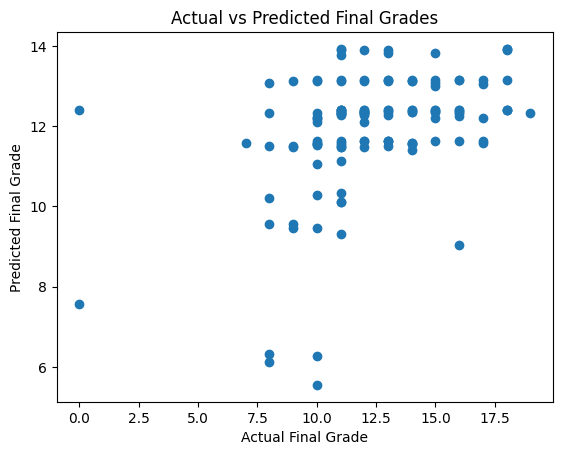

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(y_test, predictions)

plt.xlabel("Actual Final Grade")
plt.ylabel("Predicted Final Grade")
plt.title("Actual vs Predicted Final Grades")

plt.show()

In [ ]:
print(X.columns)

Index(['studytime', 'failures', 'absences'], dtype='object')


In [ ]:
X = student_performance.data.features[
    [
        "studytime",
        "failures",
        "absences",
        "Medu",
        "Fedu",
        "traveltime",
        "famrel",
        "freetime",
        "goout",
        "Dalc",
        "Walc",
        "health"
    ]
]

print(X.head())

   studytime  failures  absences  Medu  Fedu  traveltime  famrel  freetime  \
0          2         0         4     4     4           2       4         3   
1          2         0         2     1     1           1       5         3   
2          2         0         6     1     1           1       4         3   
3          3         0         0     4     2           1       3         2   
4          2         0         0     3     3           1       4         3   

   goout  Dalc  Walc  health  
0      4     1     1       3  
1      3     1     1       3  
2      2     2     3       3  
3      2     1     1       5  
4      2     1     2       5  


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 519
Testing rows: 130


In [ ]:
model2 = LinearRegression()

model2.fit(X_train, y_train)

LinearRegression()

In [ ]:
predictions2 = model2.predict(X_test)

print(predictions2[:10])

[13.68152854 11.5692205  13.57285696 14.19138737 10.9106789  14.01195489
 13.25576107  6.65176018 12.22023747 11.49560461]


In [ ]:
error2 = mean_absolute_error(y_test, predictions2)

print("Model 2 MAE:", error2)

Model 2 MAE: 2.1331631494735706


In [ ]:
score2 = r2_score(y_test, predictions2)

print("Model 2 R² Score:", score2)

Model 2 R² Score: 0.17221562983707583


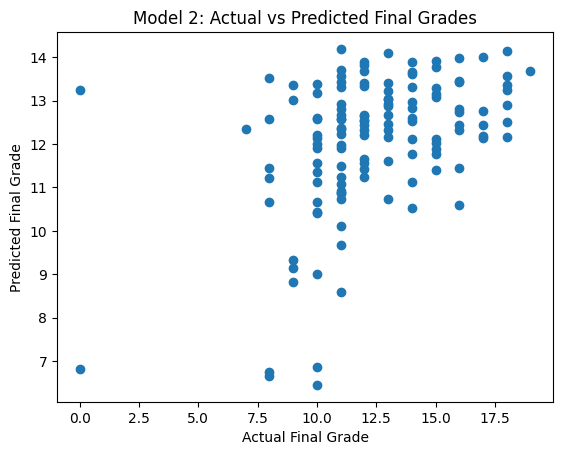

In [ ]:
plt.scatter(y_test, predictions2)

plt.xlabel("Actual Final Grade")
plt.ylabel("Predicted Final Grade")
plt.title("Model 2: Actual vs Predicted Final Grades")

plt.show()

In [ ]:
comparison = {
    "Model": ["Model 1", "Model 2"],
    "MAE": [error, error2],
    "R2": [score, score2]
}

comparison_df = pd.DataFrame(comparison)

print(comparison_df)

     Model       MAE        R2
0  Model 1  2.206036  0.149564
1  Model 2  2.133163  0.172216


In [ ]:
import pandas as pd

In [ ]:
comparison = {
    "Model": ["Model 1", "Model 2"],
    "MAE": [error, error2],
    "R2": [score, score2]
}

comparison_df = pd.DataFrame(comparison)

print(comparison_df)

     Model       MAE        R2
0  Model 1  2.206036  0.149564
1  Model 2  2.133163  0.172216


In [ ]:
import pandas as pd

In [ ]:
new_student = pd.DataFrame({
    "studytime": [3],
    "failures": [0],
    "absences": [4],
    "Medu": [3],
    "Fedu": [3],
    "traveltime": [1],
    "famrel": [4],
    "freetime": [3],
    "goout": [2],
    "Dalc": [1],
    "Walc": [1],
    "health": [4]
})

new_prediction = model2.predict(new_student)

print("Predicted Final Grade:", new_prediction[0])

Predicted Final Grade: 13.609467379814076
